In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
os.environ['AUTO_DIR'] = '<path-to-auto-07p>'  # Required for bifurcation_finder (see docs/INSTALL_AUTO.md)


In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from pprint import pprint

from tipbox.bifurcation.polynomial_model import generate_random_polynomial_model, simulate_to_equilibrium
from tipbox.bifurcation.bifurcation_finder import find_all_bifurcations


# Individual components
1. Randomly generate polynomials
2. Find bifurcation (using AUTO-07p)
3. Generate stochastic simulations

### 1. Generate polynomial models

In [3]:
# Generate a random polynomial model until convergence is reached (max_attempts=100)
key = jax.random.PRNGKey(0)
model = generate_random_polynomial_model(key, max_attempts=100)

if model is not None:
    print(f"Converged with equilibrium at: {model.equi}")

W0000 00:00:1762715927.691897 20228131 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1762715927.726894 20228131 service.cc:145] XLA service 0x1290cbb10 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1762715927.727048 20228131 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1762715927.729153 20228131 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1762715927.729161 20228131 mps_client.cc:384] XLA backend will use up to 5726240768 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M1

systemMemory: 8.00 GB
maxCacheSize: 2.67 GB

Converged with equilibrium at: [-1.0533764 -0.810535 ]


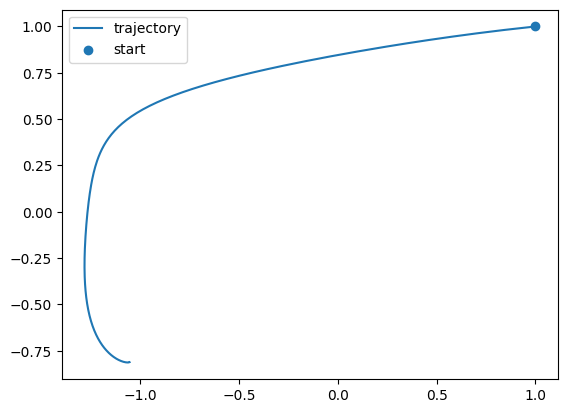

In [4]:
# Visually inspect the model trajectory
s0 = jnp.array([1.0, 1.0])

equi_pt, is_converged, traj = simulate_to_equilibrium(
    model.pars_a, model.pars_b, s0
)

# Plot the trajectory
plt.plot(traj[:, 0], traj[:, 1], label="trajectory")
plt.scatter(traj[0, 0], traj[0, 1], color='C0', label="start")
plt.legend()
plt.show();


### 2. Find Bifurcation

In [5]:
bifurcations = find_all_bifurcations(
    model,
    param_range=(-5.0, 5.0)
)

Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a1         L2-NORM          x             y       
   1    43  LP    2   1.02742E-01   3.57972E-01  -1.16271E-01  -3.38563E-01
   1    49  LP    3  -7.90746E-03   7.30199E-02  -1.70545E-03   7.30000E-02
   1   115  UZ    4   5.00000E+00   1.47223E+00   1.21907E+00   8.25419E-01

 Total Time    0.657E-02
model ... done
Saving to b.outa1, s.outa1, and d.outa1 ... done
Deleting fort.* *.o *.exe *.*~ ... done
Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a3         L2-NORM          x             y       
   1    54  UZ    2   5.00000E+00   1.84683E+00  -1.58291E+00  -9.51408E-01

 Total Time

In [6]:
bifurcations

[BifurcationPoint(bif_type='fold', bif_param_name='a1', bif_param_index=0, bif_value=0.10274155754),
 BifurcationPoint(bif_type='null', bif_param_name='a3', bif_param_index=2, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='a6', bif_param_index=5, bif_value=0.0),
 BifurcationPoint(bif_type='fold', bif_param_name='a7', bif_param_index=6, bif_value=0.20517743069),
 BifurcationPoint(bif_type='null', bif_param_name='a9', bif_param_index=8, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='a10', bif_param_index=9, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='b2', bif_param_index=11, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='b5', bif_param_index=14, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='b6', bif_param_index=15, bif_value=0.0),
 BifurcationPoint(bif_type='fold', bif_param_name='b10', bif_param_index=19, bif_value=0.55842387183)]

In [7]:
# Show bifurcations found
print(f"Found {len(bifurcations)} bifurcations:")
for i, bif in enumerate(bifurcations):
    print(f"  {i+1}. {bif.bif_type:15s} at {bif.bif_param_name} = {bif.bif_value:.3f}")

Found 10 bifurcations:
  1. fold            at a1 = 0.103
  2. null            at a3 = 0.000
  3. null            at a6 = 0.000
  4. fold            at a7 = 0.205
  5. null            at a9 = 0.000
  6. null            at a10 = 0.000
  7. null            at b2 = 0.000
  8. null            at b5 = 0.000
  9. null            at b6 = 0.000
  10. fold            at b10 = 0.558


### 3. Simulate stochastic trajectory

In [8]:
from tipbox.bifurcation.stochastic_simulator import simulate_training_trajectory

# Pick the first bifurcation (not null)
target_bif = None
for bif in bifurcations:
    if bif.bif_type != 'null':
        target_bif = bif
        break

if target_bif:
    print(f"Simulating trajectory to {target_bif.bif_type} bifurcation...")
    
    # Generate trajectory
    key, subkey = jax.random.split(key)
    result = simulate_training_trajectory(
        model, 
        target_bif, 
        subkey, 
        steps_before_transition=100,
        series_len=500
    )
    
    time, trajectory, label, sigma = result
    

Simulating trajectory to fold bifurcation...


In [9]:
trajectory.shape, label, sigma

((500, 2), 'fold', Array(0.02550844, dtype=float32))

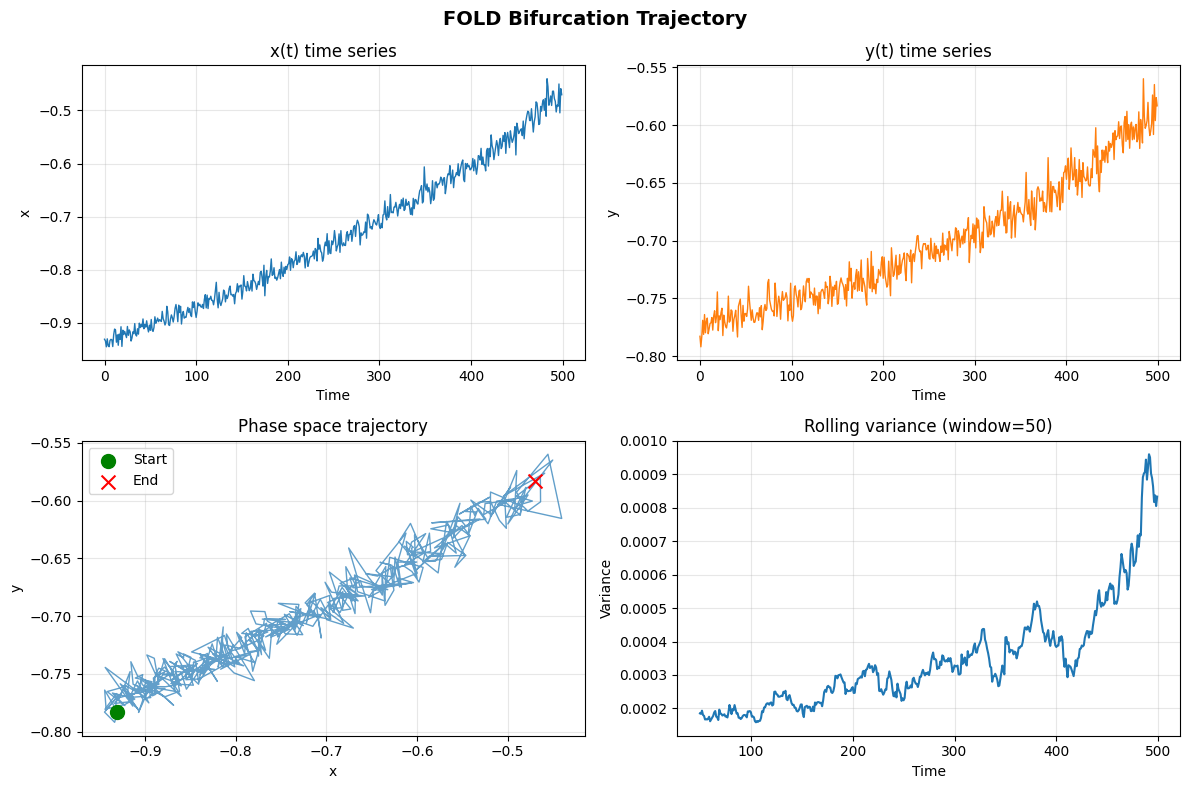

In [10]:
# Visualize the trajectory
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
# Time series of x
axes[0, 0].plot(time, trajectory[:, 0], linewidth=1)
axes[0, 0].set_xlabel('Time')
axes[0, 0].set_ylabel('x')
axes[0, 0].set_title('x(t) time series')
axes[0, 0].grid(True, alpha=0.3)

# Time series of y
axes[0, 1].plot(time, trajectory[:, 1], linewidth=1, color='C1')
axes[0, 1].set_xlabel('Time')
axes[0, 1].set_ylabel('y')
axes[0, 1].set_title('y(t) time series')
axes[0, 1].grid(True, alpha=0.3)

# Phase space
axes[1, 0].plot(trajectory[:, 0], trajectory[:, 1], linewidth=1, alpha=0.7)
axes[1, 0].scatter(trajectory[0, 0], trajectory[0, 1], s=100, c='green', 
                    marker='o', label='Start', zorder=5)
axes[1, 0].scatter(trajectory[-1, 0], trajectory[-1, 1], s=100, c='red', 
                    marker='x', label='End', zorder=5)
axes[1, 0].set_xlabel('x')
axes[1, 0].set_ylabel('y')
axes[1, 0].set_title('Phase space trajectory')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Variance over time (early warning signal)
window = 50
rolling_var = [jnp.var(trajectory[max(0, i-window):i, 0]) 
                for i in range(window, len(trajectory))]
axes[1, 1].plot(time[window:], rolling_var, linewidth=1.5)
axes[1, 1].set_xlabel('Time')
axes[1, 1].set_ylabel('Variance')
axes[1, 1].set_title(f'Rolling variance (window={window})')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle(f'{label.upper()} Bifurcation Trajectory', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# High-Level API

In [11]:
from tipbox import generate

key = jax.random.PRNGKey(123)
time, traj, info = generate.generate(
    key,
    steps_before_transition=100,
    num_timesteps=500,
    bifurcation_type='transcritical',
    null_simulation=False,
)


Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a2         L2-NORM          x             y       
   1    47  UZ    2   5.00000E+00   2.71338E+00   2.30430E+00   1.43269E+00

 Total Time    0.294E-02
model ... done
Saving to b.outa2, s.outa2, and d.outa2 ... done
Deleting fort.* *.o *.exe *.*~ ... done
Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a3         L2-NORM          x             y       
   1    58  UZ    2   5.00000E+00   2.56994E+00   2.16373E+00   1.38667E+00

 Total Time    0.397E-02
model ... done
Saving to b.outa3, s.outa3, and d.outa3 ... done
Deleting fort.* *.o *.exe *.*~ ... done
Runner configured
Runner configure

In [12]:
pprint(info)

{'bifurcation': BifurcationPoint(bif_type='transcritical',
                                 bif_param_name='b5',
                                 bif_param_index=14,
                                 bif_value=4.5087465979),
 'bifurcation_type': 'transcritical',
 'model': PolynomialModel(pars_a=Array([ 0.60716975,  0.51485264, -0.10658372,  0.63440895,  0.        ,
       -0.2989462 , -0.38937247, -0.        , -0.6316599 , -0.        ],      dtype=float32),
                          pars_b=Array([ 0.        ,  0.        , -0.39759177,  0.        , -1.0724171 ,
        0.        , -0.        , -1.7844235 , -0.        , -0.        ],      dtype=float32),
                          s0=Array([-2.133865, -3.617391], dtype=float32),
                          equi=Array([2.4352255, 0.       ], dtype=float32),
                          recovery_rate=3.009169340133667),
 'sigma': Array(0.02520891, dtype=float32),
 'steps_before_transition': 100}


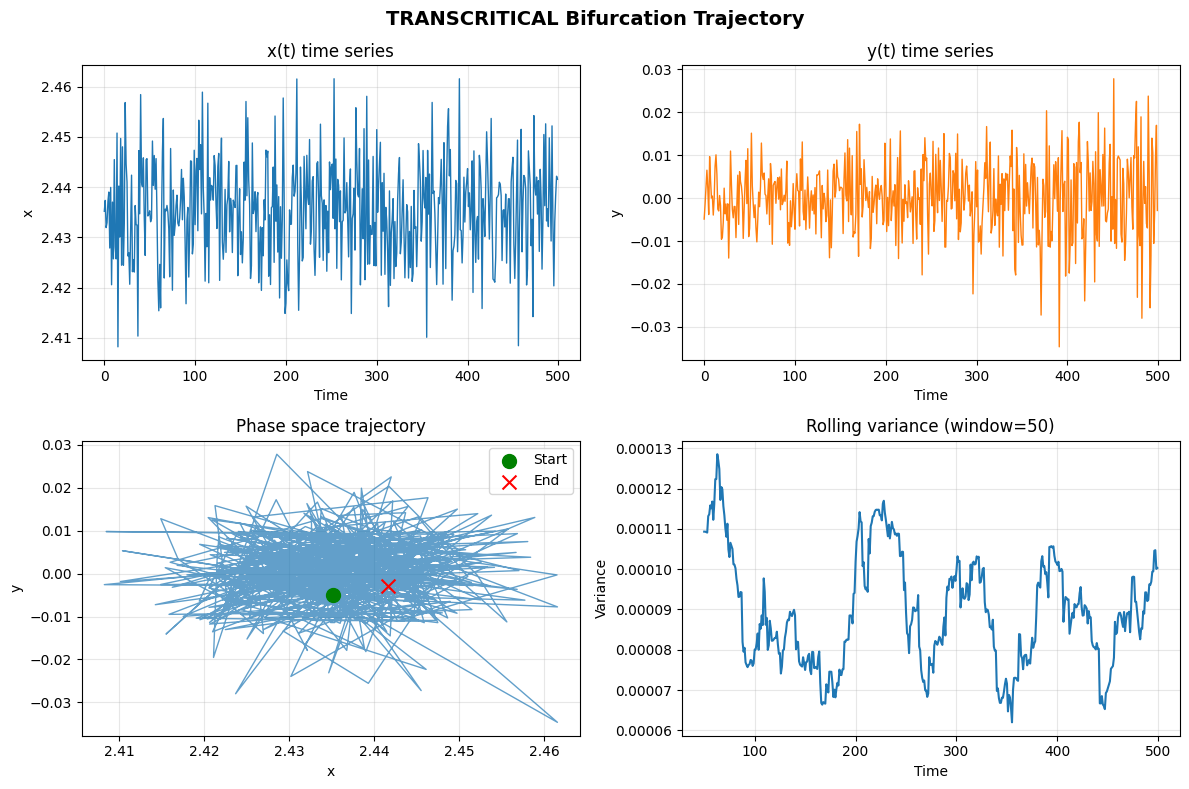

In [13]:
# Visualize the trajectory
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
# Time series of x
axes[0, 0].plot(time, traj[:, 0], linewidth=1)
axes[0, 0].set_xlabel('Time')
axes[0, 0].set_ylabel('x')
axes[0, 0].set_title('x(t) time series')
axes[0, 0].grid(True, alpha=0.3)

# Time series of y
axes[0, 1].plot(time, traj[:, 1], linewidth=1, color='C1')
axes[0, 1].set_xlabel('Time')
axes[0, 1].set_ylabel('y')
axes[0, 1].set_title('y(t) time series')
axes[0, 1].grid(True, alpha=0.3)

# Phase space
axes[1, 0].plot(traj[:, 0], traj[:, 1], linewidth=1, alpha=0.7)
axes[1, 0].scatter(traj[0, 0], traj[0, 1], s=100, c='green', 
                    marker='o', label='Start', zorder=5)
axes[1, 0].scatter(traj[-1, 0], traj[-1, 1], s=100, c='red', 
                    marker='x', label='End', zorder=5)
axes[1, 0].set_xlabel('x')
axes[1, 0].set_ylabel('y')
axes[1, 0].set_title('Phase space trajectory')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Variance over time (early warning signal)
window = 50
rolling_var = [jnp.var(traj[max(0, i-window):i, 0]) 
                for i in range(window, len(traj))]
axes[1, 1].plot(time[window:], rolling_var, linewidth=1.5)
axes[1, 1].set_xlabel('Time')
axes[1, 1].set_ylabel('Variance')
axes[1, 1].set_title(f'Rolling variance (window={window})')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle(f'{info["bifurcation_type"].upper()} Bifurcation Trajectory', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
